---
# <div align="center"><font color='red'>  </font></div>
# <div align="center"><font color='red'> COSC2779 | Deep Learning  </font></div>
## <div align="center"> <font color='red'> Week 10 Lecture Example: **Generative Models** — AE → VAE → GAN → Diffusion</font></div>
---

Generative models learn the *distribution* of the data so we can **draw new samples** from it. This notebook builds the four ideas from the lecture, from scratch, on **toy datasets** small enough that we can *see* the distribution being learned rather than chase image quality.

Two toy datasets:
- **8×8 digits** (`sklearn.load_digits`, no download) — tiny images for the autoencoder / VAE.
- **two-moons** (2-D points) — perfect for *watching* a distribution get learned, used for the GAN and diffusion parts.

The arc: **Autoencoder** (compress) → **VAE** (a latent you can sample) → **GAN** (adversarial) → **Diffusion** (iterative denoising).

# Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.datasets import load_digits, make_moons

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)
torch.manual_seed(0); np.random.seed(0)

def scatter2d(ax, pts, title, color='tab:blue'):
    ax.scatter(pts[:, 0], pts[:, 1], s=4, alpha=0.4, c=color)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect('equal')

Using device: cpu


# Part 1 — Autoencoder: compress, then reconstruct

An autoencoder squeezes each image through a narrow **bottleneck** and reconstructs it. The **encoder** learns a compact code; the **decoder** learns to invert it. We use a **2-D bottleneck** so we can plot the latent space.

```
 input        encoder                bottleneck              decoder        reconstruction
 (8×8)                                 z ∈ ℝ²
┌───────┐   ┌──────┐   ┌──────┐      ┌──────┐      ┌──────┐   ┌──────┐      ┌───────┐
│  64   │──▶│  32  │──▶│ ReLU │──▶┌─▶│  2   │─┐──▶ │  32  │──▶│ ReLU │──▶   │  64   │
│ pixels│   │Linear│   │      │   │  │ code │ │    │Linear│   │ +Lin │      │Sigmoid│
└───────┘   └──────┘   └──────┘   │  └──────┘ │    └──────┘   └──────┘      └───────┘
                                  │           │
            ── compress ──────────┘           └──────── reconstruct ──────────▶
                (64 → 32 → 2)                            (2 → 32 → 64)

            trained to minimise   ‖ input − reconstruction ‖²   (MSE)
```

**Read it as:** each 8×8 image is flattened to 64 numbers, squeezed down to just **2** (the code we can plot), then expanded back to 64 and reshaped to 8×8. The whole thing is trained so the output matches the input — nothing tells it what a "digit" is; the bottleneck forces it to keep only what's needed to reconstruct.

In [2]:
digits = load_digits()
Xd = torch.tensor((digits.data / 16.0).astype(np.float32))    # (1797, 64), in [0,1]
yd = digits.target
print('digits:', Xd.shape, '-> 8x8 images in [0,1]')

class Autoencoder(nn.Module):
    def __init__(self, z=2):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, z))
        self.dec = nn.Sequential(nn.Linear(z, 32), nn.ReLU(), nn.Linear(32, 64), nn.Sigmoid())
    def forward(self, x):
        z = self.enc(x); return self.dec(z), z

ae = Autoencoder().to(device); opt = torch.optim.Adam(ae.parameters(), 1e-2)
Xd = Xd.to(device)
for epoch in range(150):
    opt.zero_grad(); xr, _ = ae(Xd); loss = F.mse_loss(xr, Xd); loss.backward(); opt.step()
print(f'final reconstruction MSE: {loss.item():.4f}')

digits: torch.Size([1797, 64]) -> 8x8 images in [0,1]
final reconstruction MSE: 0.0467


### Reconstructions and the 2-D latent

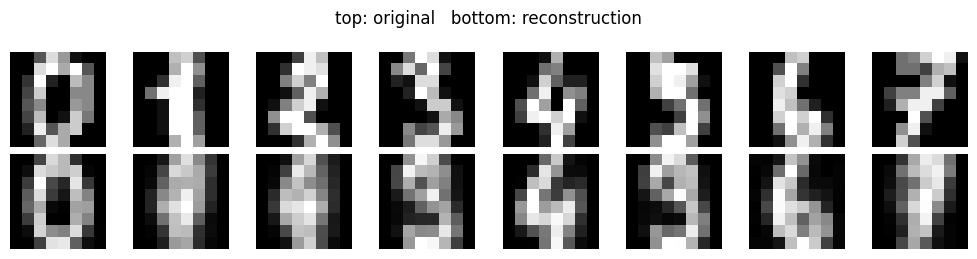

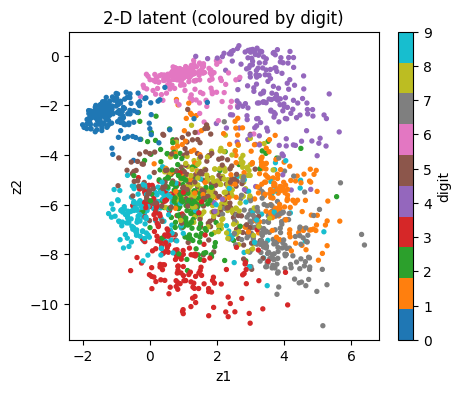

In [3]:
ae.eval()
with torch.no_grad():
    xr, z = ae(Xd)
xr = xr.cpu().numpy().reshape(-1, 8, 8); z = z.cpu().numpy(); orig = Xd.cpu().numpy().reshape(-1, 8, 8)

fig, axes = plt.subplots(2, 8, figsize=(10, 2.6))
for i in range(8):
    axes[0, i].imshow(orig[i], cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(xr[i],  cmap='gray'); axes[1, i].axis('off')
axes[0, 0].set_ylabel('orig'); axes[1, 0].set_ylabel('recon')
plt.suptitle('top: original   bottom: reconstruction'); plt.tight_layout(); plt.show()

plt.figure(figsize=(5, 4))
sc = plt.scatter(z[:, 0], z[:, 1], c=yd, cmap='tab10', s=8)
plt.colorbar(sc, label='digit'); plt.title('2-D latent (coloured by digit)')
plt.xlabel('z1'); plt.ylabel('z2'); plt.show()

**What is your judgment?** Reconstructions are recognisable and the latent organises the digits. But if we try to **generate** by sampling a random point in this latent, we usually get junk — the encoder packed the data into arbitrary regions with gaps and no consistent scale. The autoencoder compresses; it is not (yet) a *generative* model. That is what the VAE fixes.

# Part 2 — Variational Autoencoder: a latent you can sample

The VAE makes the latent **well-behaved for sampling** by (1) encoding each input as a *distribution* $\mathit{N}(\mu, \sigma^2)$ rather than a point, and (2) adding a **KL term** that pulls those distributions toward a standard normal $\mathit{N}(0, I)$. Training uses the **reparameterisation trick**, $z = \mu + \sigma \odot \epsilon$, so gradients flow through the sampling.

Loss $=$ reconstruction $+$ KL:  $\;\mathit{L} = \mathbb{E}[-\log p(x|z)] + D_{KL}\!\big(\mathit{N}(\mu,\sigma^2)\,\|\,\mathit{N}(0,I)\big).$

In [4]:
class VAE(nn.Module):
    def __init__(self, z=2):
        super().__init__(); self.z = z
        self.enc = nn.Sequential(nn.Linear(64, 64), nn.ReLU())
        self.fc_mu = nn.Linear(64, z); self.fc_logvar = nn.Linear(64, z)
        self.dec = nn.Sequential(nn.Linear(z, 64), nn.ReLU(), nn.Linear(64, 64), nn.Sigmoid())
    def forward(self, x):
        h = self.enc(x); mu = self.fc_mu(h); logvar = self.fc_logvar(h)
        std = torch.exp(0.5 * logvar)
        z = mu + std * torch.randn_like(std)        # reparameterisation trick
        return self.dec(z), mu, logvar

vae = VAE().to(device); opt = torch.optim.Adam(vae.parameters(), 1e-3)
for epoch in range(300):
    opt.zero_grad(); xr, mu, logvar = vae(Xd)
    recon = F.binary_cross_entropy(xr, Xd, reduction='sum') / len(Xd)
    kl = -0.5 * torch.mean(torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1))
    (recon + kl).backward(); opt.step()
print(f'recon={recon.item():.2f}  kl={kl.item():.3f}')

recon=24.93  kl=1.512


### Now we can generate: sample $z \sim \mathit{N}(0, I)$ and decode

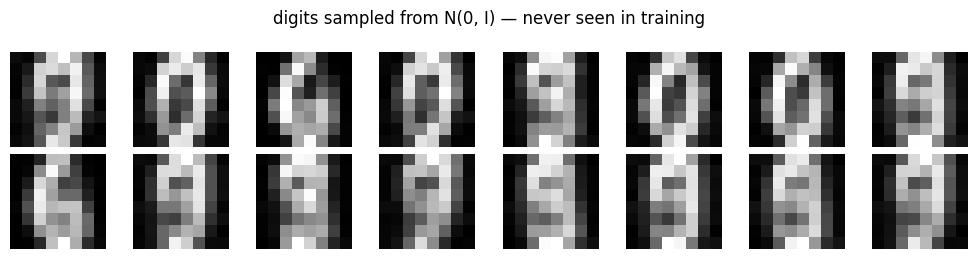

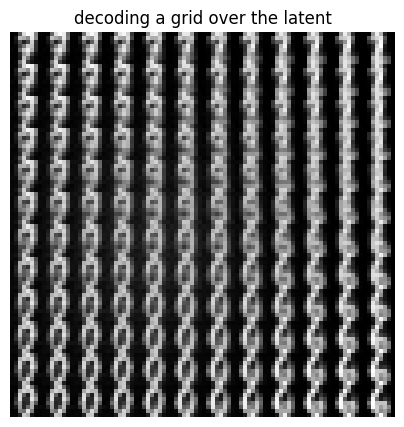

In [5]:
vae.eval()
with torch.no_grad():
    gen = vae.dec(torch.randn(16, 2).to(device)).cpu().numpy().reshape(-1, 8, 8)
fig, axes = plt.subplots(2, 8, figsize=(10, 2.6))
for i, ax in enumerate(axes.flat):
    ax.imshow(gen[i], cmap='gray'); ax.axis('off')
plt.suptitle('digits sampled from N(0, I) — never seen in training'); plt.tight_layout(); plt.show()

# a grid walk across the 2-D latent
g = 12; grid = np.linspace(-2, 2, g)
canvas = np.zeros((8 * g, 8 * g))
with torch.no_grad():
    for i, y in enumerate(grid):
        for j, x in enumerate(grid):
            img = vae.dec(torch.tensor([[x, y]], dtype=torch.float32).to(device)).cpu().numpy().reshape(8, 8)
            canvas[i*8:(i+1)*8, j*8:(j+1)*8] = img
plt.figure(figsize=(5, 5)); plt.imshow(canvas, cmap='gray')
plt.title('decoding a grid over the latent'); plt.axis('off'); plt.show()

**What is your judgment?** Sampling $\mathit{N}(0, I)$ now yields plausible digits, and the latent varies *smoothly* — the KL term made the space samplable. VAE samples tend to be a little **blurry** (the reconstruction loss averages). GANs and diffusion attack that blurriness in different ways.

# Part 3 — GAN: a generator vs a discriminator

We switch to the 2-D **two-moons** data so we can *watch* the learned distribution. A **generator** $G$ maps noise to points; a **discriminator** $D$ tries to tell real points from generated ones. They play a minimax game — $G$ learns to fool $D$ — and at the end $G$'s samples should cover the moons.

In [6]:
Xm, _ = make_moons(3000, noise=0.05)
Xm = ((Xm - Xm.mean(0)) / Xm.std(0)).astype(np.float32)
Xmt = torch.tensor(Xm).to(device)

def mlp(sizes, out_act=None):
    layers = []
    for i in range(len(sizes) - 1):
        layers += [nn.Linear(sizes[i], sizes[i+1])]
        if i < len(sizes) - 2: layers += [nn.ReLU()]
    if out_act: layers += [out_act]
    return nn.Sequential(*layers)

G = mlp([2, 64, 64, 2]).to(device)
Dsc = mlp([2, 64, 64, 1]).to(device)
og = torch.optim.Adam(G.parameters(), 2e-4, betas=(0.5, 0.9))
od = torch.optim.Adam(Dsc.parameters(), 2e-4, betas=(0.5, 0.9))
bce = nn.BCEWithLogitsLoss()

snapshots = {}
for it in range(4000):
    idx = torch.randint(0, len(Xmt), (256,)); real = Xmt[idx]
    fake = G(torch.randn(256, 2, device=device)).detach()
    od.zero_grad()
    ld = bce(Dsc(real), torch.ones(256, 1, device=device)) + bce(Dsc(fake), torch.zeros(256, 1, device=device))
    ld.backward(); od.step()
    og.zero_grad()
    lg = bce(Dsc(G(torch.randn(256, 2, device=device))), torch.ones(256, 1, device=device))
    lg.backward(); og.step()
    if it in (0, 500, 4000 - 1):
        with torch.no_grad():
            snapshots[it] = G(torch.randn(1500, 2, device=device)).cpu().numpy()
print('trained GAN')

trained GAN


### Watch the generator's samples move onto the data

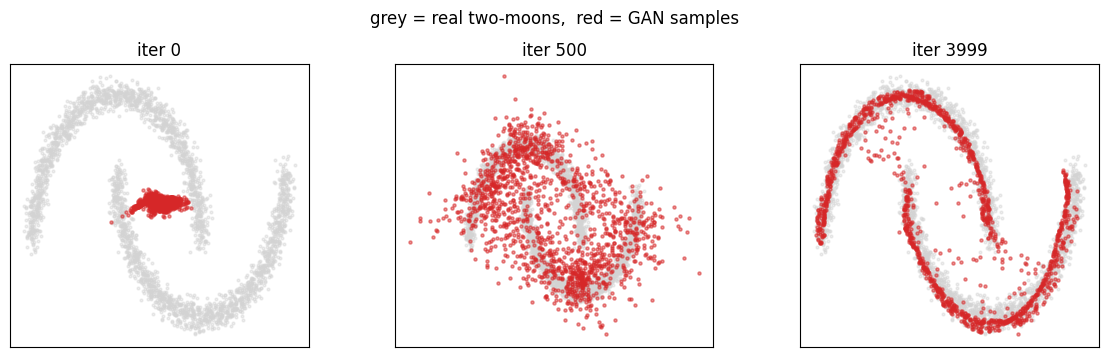

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, it in zip(axes, sorted(snapshots)):
    scatter2d(ax, Xm, '', color='lightgray')                 # real (grey) underneath
    ax.scatter(snapshots[it][:, 0], snapshots[it][:, 1], s=5, alpha=0.5, c='tab:red')
    ax.set_title(f'iter {it}')
plt.suptitle('grey = real two-moons,  red = GAN samples'); plt.tight_layout(); plt.show()

**What is your judgment?** The generator's red points migrate onto the grey moons — sharp samples with no reconstruction blur. But GANs are **finicky and unstable**: the adversarial balance is delicate, and a common failure is **mode collapse** — the generator produces only part of the distribution (e.g. one moon) because that alone fools $D$. Watch for the red points covering *both* moons; if they pile onto one, that's collapse. Diffusion avoids this game entirely.

# Part 4 — Diffusion: learn to denoise

Diffusion breaks generation into many easy steps. A **fixed forward process** slowly turns data into Gaussian noise; a network learns the **reverse** — remove a little noise at each step. We build a DDPM on the two-moons data.

**Forward (no learning):** with schedule $\beta_t$, $\alpha_t = 1-\beta_t$, $\bar\alpha_t = \prod_{s\le t}\alpha_s$, we can jump to any step in one shot:
$$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon,\qquad \epsilon \sim \mathit{N}(0, I).$$

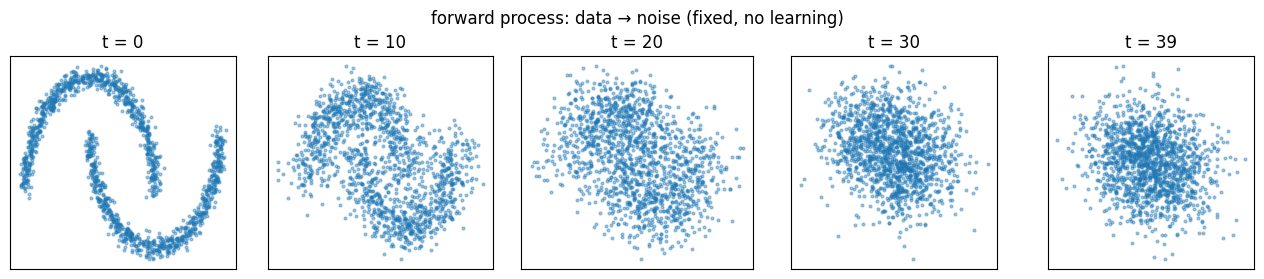

In [8]:
T = 40
betas = torch.linspace(1e-4, 0.05, T).to(device)
alphas = 1 - betas
abar = torch.cumprod(alphas, 0)

# show the forward process dissolving the data into noise
fig, axes = plt.subplots(1, 5, figsize=(13, 2.8))
x0 = Xmt[:1500]
for ax, t in zip(axes, [0, 10, 20, 30, 39]):
    xt = (abar[t].sqrt() * x0 + (1 - abar[t]).sqrt() * torch.randn_like(x0)).cpu().numpy()
    scatter2d(ax, xt, f't = {t}')
plt.suptitle('forward process: data → noise (fixed, no learning)'); plt.tight_layout(); plt.show()

**Reverse (learned):** a small MLP predicts the noise $\epsilon_\theta(x_t, t)$ that was added, trained with a plain MSE loss:
$$\mathit{L} = \mathbb{E}_{x_0, t, \epsilon}\big[\,\|\epsilon - \epsilon_\theta(x_t, t)\|^2\,\big].$$
(The image version of this network is a **U-Net**; here 2-D points only need an MLP.)

In [9]:
class NoisePredictor(nn.Module):
    def __init__(self, d=128):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2 + 1, d), nn.ReLU(),
                                 nn.Linear(d, d), nn.ReLU(), nn.Linear(d, 2))
    def forward(self, x, t):
        t_feat = (t.float() / T).unsqueeze(1)          # tell the net which step it is
        return self.net(torch.cat([x, t_feat], dim=1))

eps_model = NoisePredictor().to(device)
opt = torch.optim.Adam(eps_model.parameters(), 1e-3)
for it in range(6000):
    idx = torch.randint(0, len(Xmt), (256,)); x0 = Xmt[idx]
    t = torch.randint(0, T, (256,), device=device); noise = torch.randn_like(x0)
    xt = abar[t].sqrt().unsqueeze(1) * x0 + (1 - abar[t]).sqrt().unsqueeze(1) * noise
    opt.zero_grad(); F.mse_loss(eps_model(xt, t), noise).backward(); opt.step()
print('trained the noise predictor')

trained the noise predictor


### Sampling: start from noise and denoise step by step

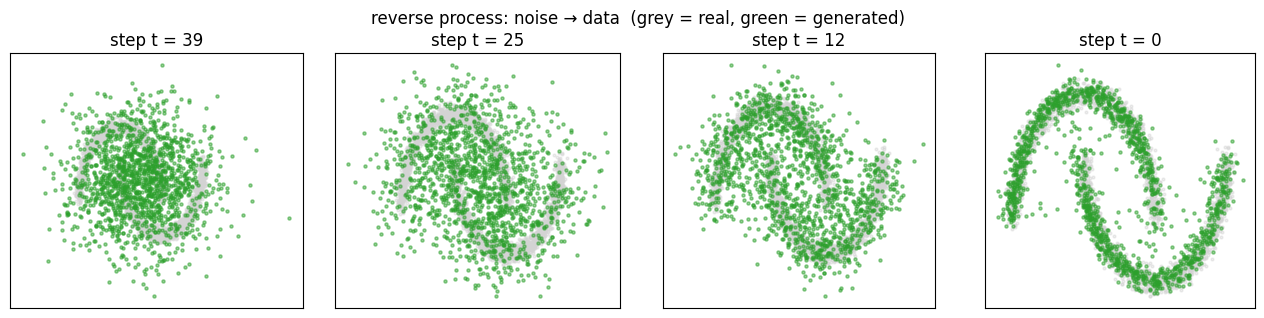

In [10]:
@torch.no_grad()
def sample(n, keep=(39, 25, 12, 0)):
    x = torch.randn(n, 2, device=device); snaps = {}
    for ti in reversed(range(T)):
        t = torch.full((n,), ti, device=device)
        e = eps_model(x, t); a, ab = alphas[ti], abar[ti]
        x = (x - (1 - a) / (1 - ab).sqrt() * e) / a.sqrt()
        if ti > 0: x = x + betas[ti].sqrt() * torch.randn_like(x)
        if ti in keep: snaps[ti] = x.cpu().numpy()
    return snaps

snaps = sample(1500)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, ti in zip(axes, [39, 25, 12, 0]):
    scatter2d(ax, Xm, '', color='lightgray')
    ax.scatter(snaps[ti][:, 0], snaps[ti][:, 1], s=5, alpha=0.5, c='tab:green')
    ax.set_title(f'step t = {ti}')
plt.suptitle('reverse process: noise → data  (grey = real, green = generated)'); plt.tight_layout(); plt.show()

**What is your judgment?** Starting from pure noise (left), the reverse steps pull the green points onto **both** moons — high quality *and* good coverage, from a stable regression loss with no adversarial game. The price is **speed**: we ran the network `T` times to draw one batch. Real image models use a U-Net for $\epsilon_\theta$ and add **conditioning/guidance** to steer generation toward a prompt (Part where the lecture's "Y = Dog" slide comes in).

# Wrap-up: three ways to generate

| | **VAE / Autoencoder** | **GAN** | **Diffusion** |
|---|---|---|---|
| idea | encode–decode | generator vs discriminator | iterative denoising |
| training | stable | **unstable** (adversarial) | **stable** (regression) |
| sample quality | blurry | sharp | sharp |
| diversity / coverage | good | mode-collapse risk | **excellent** |
| sampling speed | **fast** (1 pass) | **fast** (1 pass) | slow (many steps) |

We built each on toy data so the mechanics are visible: a **bottleneck** (AE), a **samplable latent** (VAE), an **adversarial game** (GAN), and **iterative denoising** (diffusion). The image versions swap our MLPs for CNNs/U-Nets, but the ideas are exactly these.

**Exercises**
* Sample a random point in the plain **autoencoder's** latent and decode it — compare to the VAE. Why is it worse?
* Reduce the GAN's generator capacity or train $D$ too well — can you induce **mode collapse** (only one moon)?
* Change the diffusion schedule `T` (e.g. 10 vs 100) — how do sample quality and speed trade off?
* Add a **class label** to the two-moons diffusion (condition `eps_model` on which moon) and generate a chosen moon.